In [ ]:
import zipfile
import os

zip_path = "/content/EUVP.zip"
extract_path = "/content/EUVP"

# Unzip only if not already extracted
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("✅ Dataset extracted successfully!")
else:
    print("✅ Dataset already extracted.")


✅ Dataset extracted successfully!


In [ ]:
import os
from PIL import Image
from tqdm import tqdm

# Base input and output directories
base_in = "/content/EUVP"        # original dataset
base_out = "/content/EUVP_224"   # resized dataset

# Folders to process
folders = [
    "Paired/underwater_dark/trainA",
    "Paired/underwater_dark/trainB",
    "Paired/underwater_dark/validationA",
    "Paired/underwater_dark/validationB"

]

# Resize function
def resize_and_save(in_dir, out_dir, size=(224, 224)):
    os.makedirs(out_dir, exist_ok=True)
    for fname in tqdm(os.listdir(in_dir), desc=f"Resizing {in_dir}"):
        in_path = os.path.join(in_dir, fname)
        out_path = os.path.join(out_dir, fname)

        try:
            img = Image.open(in_path).convert("RGB")
            img = img.resize(size, Image.BICUBIC)  # high-quality resize
            img.save(out_path)
        except Exception as e:
            print(f"❌ Skipped {fname}: {e}")

# Process each folder
for folder in folders:
    in_dir = os.path.join(base_in, folder)
    out_dir = os.path.join(base_out, folder)
    resize_and_save(in_dir, out_dir)

print("✅ All dataset images resized and saved under /content/EUVP_224/")


Resizing /content/EUVP/Paired/underwater_dark/trainA: 100%|██████████| 64/64 [00:00<00:00, 348.44it/s]
Resizing /content/EUVP/Paired/underwater_dark/trainB: 100%|██████████| 64/64 [00:00<00:00, 454.99it/s]
Resizing /content/EUVP/Paired/underwater_dark/validationA: 100%|██████████| 64/64 [00:00<00:00, 463.49it/s]
Resizing /content/EUVP/Paired/underwater_dark/validationB: 100%|██████████| 64/64 [00:00<00:00, 459.69it/s]

✅ All dataset images resized and saved under /content/EUVP_224/


In [ ]:
# ✅ Check GPU
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on: {device}")

# ✅ Install dependencies
!pip install timm
!pip install torchvision
!pip install matplotlib


Running on: cuda


In [ ]:
import os
import glob
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from tqdm import tqdm

In [ ]:
# ✅ Dataset path and validation
DATASET_PATH = "/content/EUVP_224"
required_dirs = [
    "Paired/underwater_dark/trainA",
    "Paired/underwater_dark/trainB",
    "Paired/underwater_dark/validationA",
    "Paired/underwater_dark/validationB"

]

for d in required_dirs:
    full_path = os.path.join(DATASET_PATH, d)
    if not os.path.exists(full_path):
        print(f"❌ Missing: {full_path}")
    else:
        print(f"✅ Found: {full_path}")


✅ Found: /content/EUVP_224/Paired/underwater_dark/trainA
✅ Found: /content/EUVP_224/Paired/underwater_dark/trainB
✅ Found: /content/EUVP_224/Paired/underwater_dark/validationA
✅ Found: /content/EUVP_224/Paired/underwater_dark/validationB


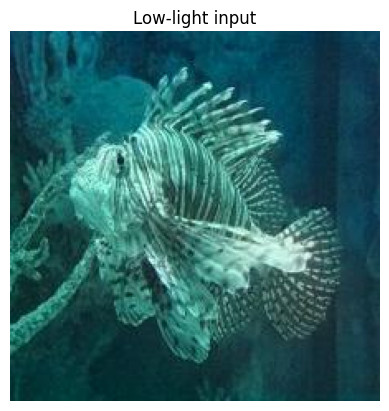

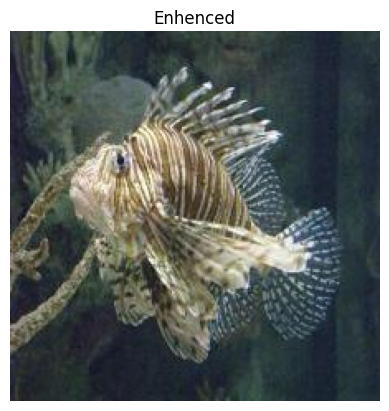

In [ ]:
class EUVPDataset(Dataset):
    def __init__(self, low_dir, high_dir, transform=None):
        self.low_paths = sorted(glob.glob(os.path.join(low_dir, '*')))
        self.high_paths = sorted(glob.glob(os.path.join(high_dir, '*')))
        self.transform = transform

    def __len__(self):
        return min(len(self.low_paths), len(self.high_paths))

    def __getitem__(self, idx):
        low_img = Image.open(self.low_paths[idx]).convert("RGB")
        high_img = Image.open(self.high_paths[idx]).convert("RGB")

        if self.transform:
            low_img = self.transform(low_img)
            high_img = self.transform(high_img)

        return low_img, high_img

# Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)  # scale to [-1,1] for Tanh
])

# Dataset paths
train_low  = os.path.join(DATASET_PATH, "Paired/underwater_dark/trainA")
train_high = os.path.join(DATASET_PATH, "Paired/underwater_dark/trainB")
val_low    = os.path.join(DATASET_PATH, "Paired/underwater_dark/validationA")
val_high   = os.path.join(DATASET_PATH, "Paired/underwater_dark/validationB")

# Datasets and DataLoaders
train_dataset = EUVPDataset(train_low, train_high, transform=transform)
train_loader  = DataLoader(train_dataset, batch_size=4, shuffle=True)

test_dataset  = EUVPDataset(val_low, val_high, transform=transform)
test_loader   = DataLoader(test_dataset, batch_size=1, shuffle=False)

# ===============================
# Visualization Helpers
# ===============================
def denorm(tensor):
    """Convert [-1,1] → [0,1] for display"""
    return (tensor * 0.5) + 0.5

to_pil = transforms.ToPILImage()

def show_tensor(img, title=""):
    img = denorm(img.detach().cpu())
    plt.imshow(to_pil(img))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

# ===============================
# Sanity check visualization
# ===============================
low, high = next(iter(train_loader))

# Show first sample of a batch
show_tensor(low[0], "Low-light input")
show_tensor(high[0], "Enhanced")

In [ ]:
# ==========================
# Test dataset
# ==========================
val_low  = "/content/EUVP/Paired/underwater_dark/validationA"
val_high = "/content/EUVP/Paired/underwater_dark/validationB"

test_dataset = EUVPDataset(val_low, val_high, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# ---------------------------
# Swin-UNet Generator
# ---------------------------
class ConvBNAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1, act=True):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, k, s, p, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.GELU() if act else nn.Identity()
    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.proj = ConvBNAct(in_ch, out_ch, k=1, s=1, p=0)
        self.conv1 = ConvBNAct(out_ch + skip_ch, out_ch)
        self.conv2 = ConvBNAct(out_ch, out_ch)
    def forward(self, x, skip):
        # Upsample x to skip's spatial size
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        x = self.proj(x)
        x = torch.cat([x, skip], dim=1)
        x = self.conv2(self.conv1(x))
        return x

class SwinUNetGenerator(nn.Module):
    """Practical Swin-UNet: Swin encoder (timm) + UNet-style decoder with skip connections."""
    def __init__(self, in_channels=3, out_channels=3, backbone="swin_tiny_patch4_window7_224"):
        super().__init__()

        # timm features_only returns a list of feature maps at multiple resolutions
        self.encoder = timm.create_model(
            backbone,
            pretrained=True,
            features_only=True,
            in_chans=in_channels,
            out_indices=(0, 1, 2, 3),  # 4 stages
        )

        enc_ch = self.encoder.feature_info.channels()  # e.g., [96,192,384,768] for swin_tiny
        c1, c2, c3, c4 = enc_ch

        # Bottleneck refine
        self.bottleneck = nn.Sequential(
            ConvBNAct(c4, c4),
            ConvBNAct(c4, c4),
        )

        # Decoder: upsample + skip
        self.up3 = UpBlock(c4, c3, c3)
        self.up2 = UpBlock(c3, c2, c2)
        self.up1 = UpBlock(c2, c1, c1)

        # Final up to input resolution (224x224 if you resized)
        self.head = nn.Sequential(
            ConvBNAct(c1, 64),
            nn.Conv2d(64, out_channels, kernel_size=1, stride=1, padding=0),
            nn.Tanh()
        )

    def forward(self, x):
        feats = self.encoder(x)  # [f1,f2,f3,f4]

        # timm versions can return either NCHW or NHWC for Swin feature maps.
        # Convert to NCHW if needed so Conv2d blocks work correctly.
        def to_nchw(t):
            if t.dim() == 4 and t.shape[1] != t.shape[-1] and t.shape[-1] in (96, 192, 384, 768):
                return t.permute(0, 3, 1, 2).contiguous()  # NHWC -> NCHW
            return t

        f1, f2, f3, f4 = [to_nchw(t) for t in feats]
        x = self.bottleneck(f4)
        x = self.up3(x, f3)
        x = self.up2(x, f2)
        x = self.up1(x, f1)
        # Up to input size
        x = F.interpolate(x, size=(x.shape[-2]*4, x.shape[-1]*4), mode="bilinear", align_corners=False)  # to 224 if f1 is 56
        x = self.head(x)
        return x

# ---------------------------
# PatchGAN Discriminator (70x70)
# ---------------------------
class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=3, ndf=64):
        super().__init__()
        def block(in_ch, out_ch, norm=True):
            layers = [nn.Conv2d(in_ch, out_ch, 4, 2, 1, bias=not norm)]
            if norm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        # input is concatenated (x,y) => 6 channels
        layers = []
        layers += block(in_channels * 2, ndf, norm=False)
        layers += block(ndf, ndf * 2)
        layers += block(ndf * 2, ndf * 4)
        layers += [nn.Conv2d(ndf * 4, ndf * 8, 4, 1, 1, bias=False),
                   nn.BatchNorm2d(ndf * 8),
                   nn.LeakyReLU(0.2, inplace=True)]
        layers += [nn.Conv2d(ndf * 8, 1, 4, 1, 1)]  # logits (NO sigmoid)

        self.model = nn.Sequential(*layers)

    def forward(self, x, y):
        return self.model(torch.cat([x, y], dim=1))

# Instantiate
G = SwinUNetGenerator().to(device)
D = PatchDiscriminator().to(device)
print('G params:', sum(p.numel() for p in G.parameters())/1e6, 'M')
print('D params:', sum(p.numel() for p in D.parameters())/1e6, 'M')


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

G params: 43.809917 M
D params: 2.768705 M


In [ ]:
g_opt = optim.Adam(G.parameters(), lr=1e-4, betas=(0.5, 0.999))
d_opt = optim.Adam(D.parameters(), lr=1e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
l1  = nn.L1Loss()

In [ ]:
import torch

# Define the device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Create the generator and discriminator models and move them to the device
model_G = SwinUNetGenerator().to(device)
model_D = PatchDiscriminator().to(device)

print("✅ Models initialized successfully!")

Using device: cuda
✅ Models initialized successfully!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Losses
bce = nn.BCEWithLogitsLoss()
l1  = nn.L1Loss()

# Optimizers (Pix2Pix defaults)
g_opt = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_opt = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

# Loss weights
lambda_l1  = 100.0   # keep structure / color fidelity
lambda_gan = 1.0     # realism via PatchGAN


In [ ]:
from tqdm import tqdm

epochs =500
for epoch in range(epochs):
    G.train(); D.train()
    d_running, g_running = 0.0, 0.0

    for low, high in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        low, high = low.to(device), high.to(device)

        # -----------------------
        # Train Discriminator
        # -----------------------
        fake = G(low).detach()

        d_real = D(low, high)
        d_fake = D(low, fake)

        d_loss_real = bce(d_real, torch.ones_like(d_real))
        d_loss_fake = bce(d_fake, torch.zeros_like(d_fake))
        d_loss = 0.5 * (d_loss_real + d_loss_fake)

        d_opt.zero_grad(set_to_none=True)
        d_loss.backward()
        d_opt.step()

        # -----------------------
        # Train Generator
        # -----------------------
        fake = G(low)
        pred_fake = D(low, fake)

        g_gan = bce(pred_fake, torch.ones_like(pred_fake))
        g_l1  = l1(fake, high)
        g_loss = lambda_gan * g_gan + lambda_l1 * g_l1

        g_opt.zero_grad(set_to_none=True)
        g_loss.backward()
        g_opt.step()

        d_running += d_loss.item()
        g_running += g_loss.item()

    print(f"Epoch {epoch+1}/{epochs} | D: {d_running/len(train_loader):.4f} | G: {g_running/len(train_loader):.4f} | (GAN {g_gan.item():.4f}, L1 {g_l1.item():.4f})")

# Save final weights
torch.save(G.state_dict(), "generator_final.pth")
torch.save(D.state_dict(), "discriminator_final.pth")


Epoch 1/500: 100%|██████████| 16/16 [00:05<00:00,  2.75it/s]


Epoch 1/500 | D: 0.7219 | G: 30.6738 | (GAN 0.7398, L1 0.2140)


Epoch 2/500: 100%|██████████| 16/16 [00:03<00:00,  5.11it/s]


Epoch 2/500 | D: 0.6669 | G: 23.5254 | (GAN 0.7995, L1 0.2099)


Epoch 3/500: 100%|██████████| 16/16 [00:03<00:00,  5.06it/s]


Epoch 3/500 | D: 0.6879 | G: 22.6429 | (GAN 0.8301, L1 0.1479)


... (990 outputs left out)

Epoch 499/500: 100%|██████████| 16/16 [00:03<00:00,  4.39it/s]


Epoch 499/500 | D: 0.0017 | G: 15.3088 | (GAN 6.7868, L1 0.0620)


Epoch 500/500: 100%|██████████| 16/16 [00:03<00:00,  4.27it/s]


Epoch 500/500 | D: 0.1051 | G: 13.8551 | (GAN 3.8960, L1 0.0685)


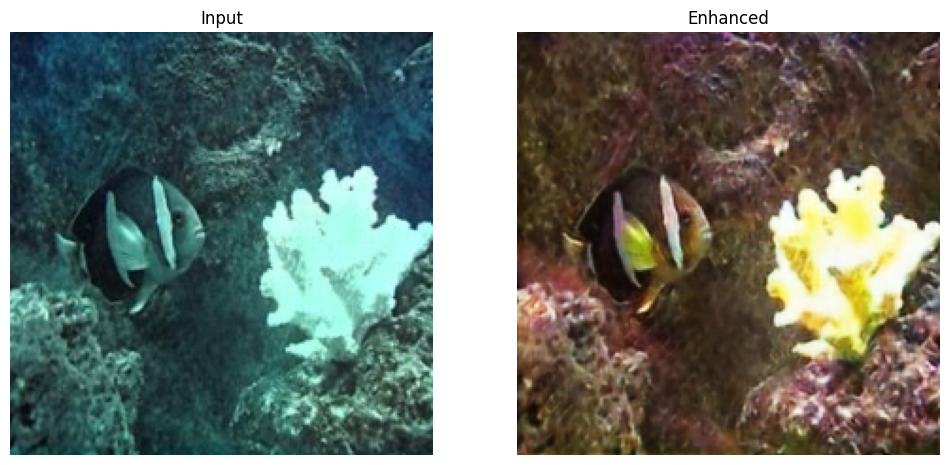

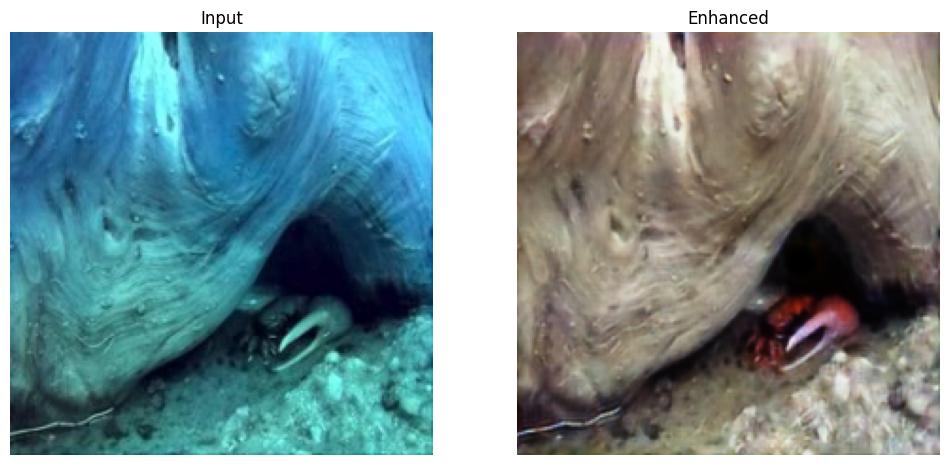

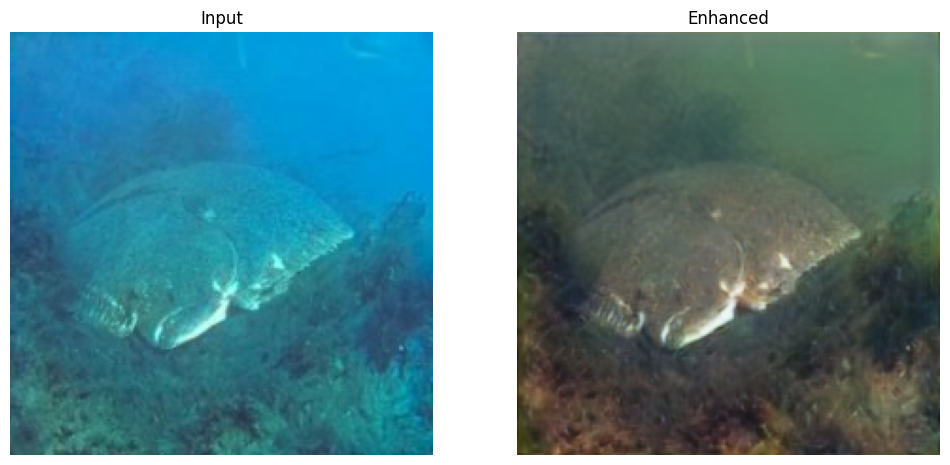

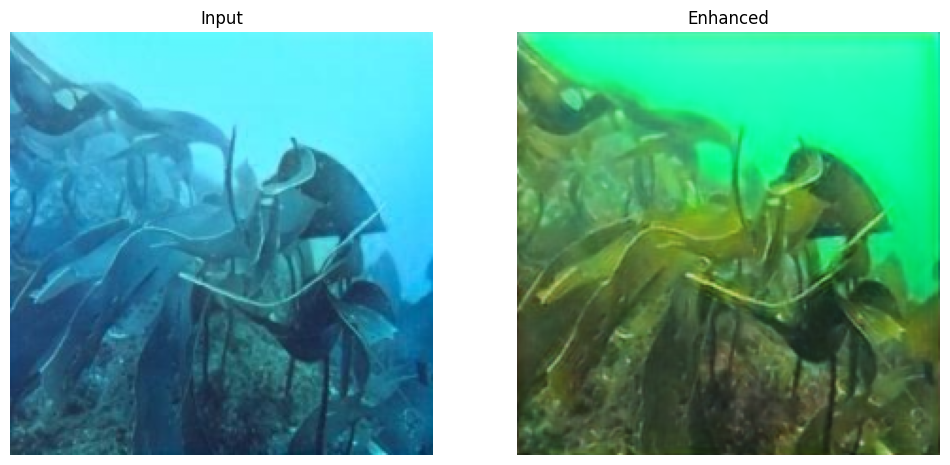

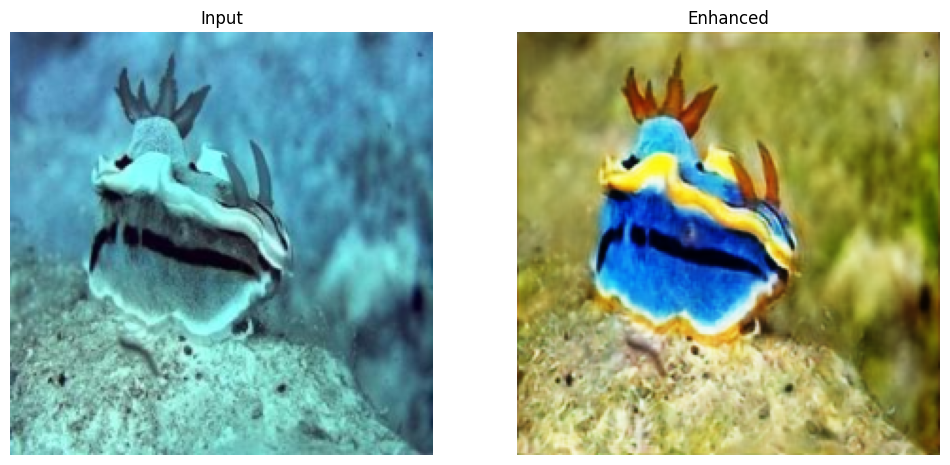

...

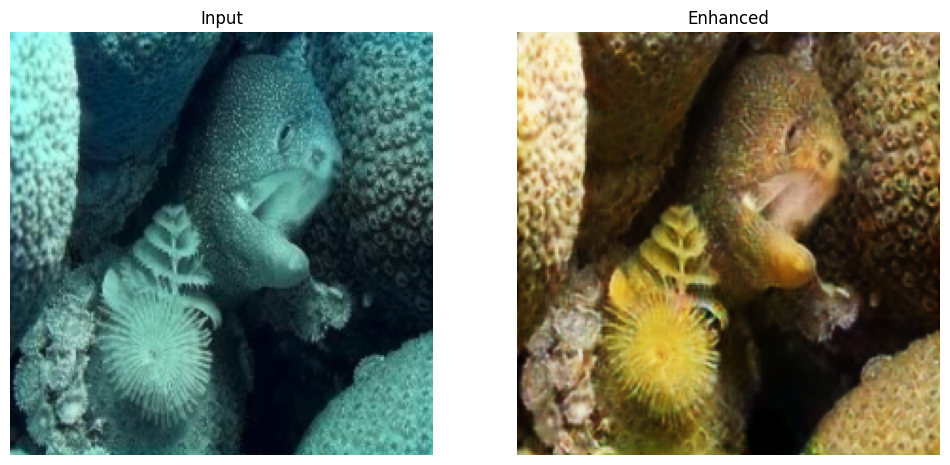

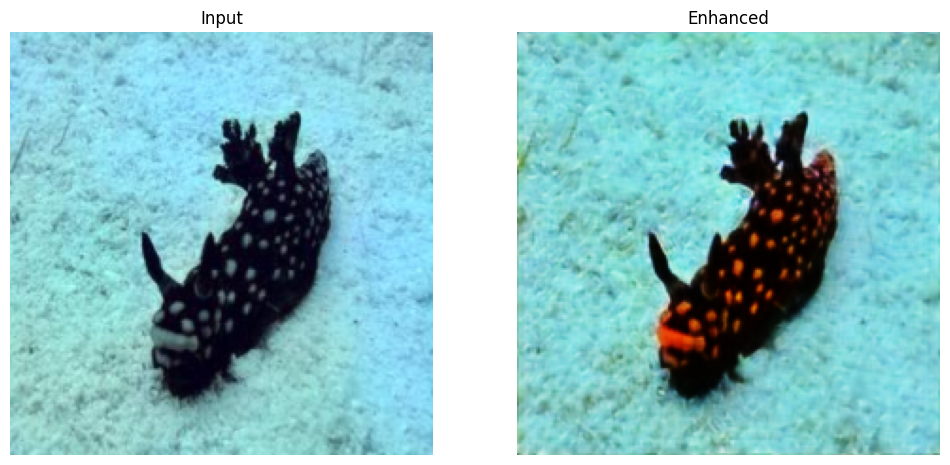

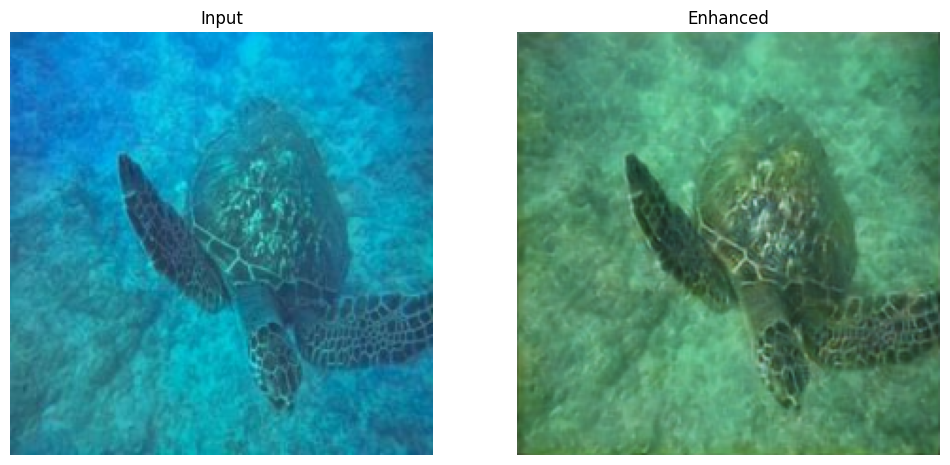

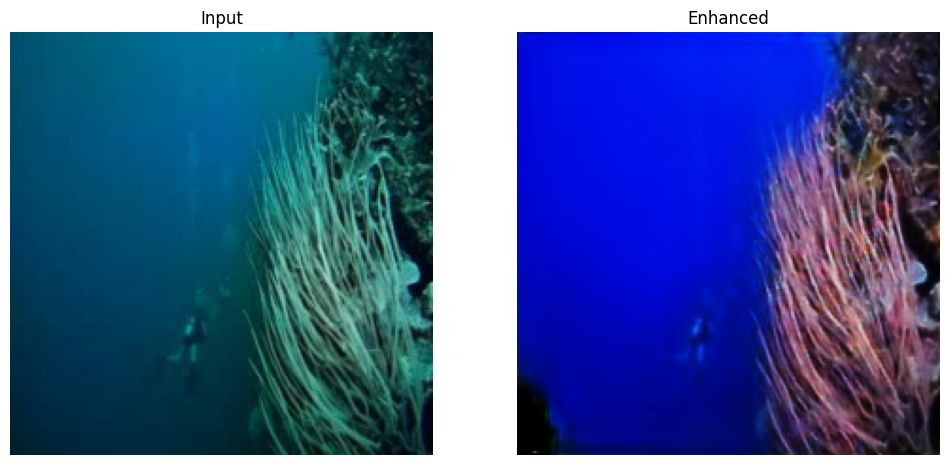

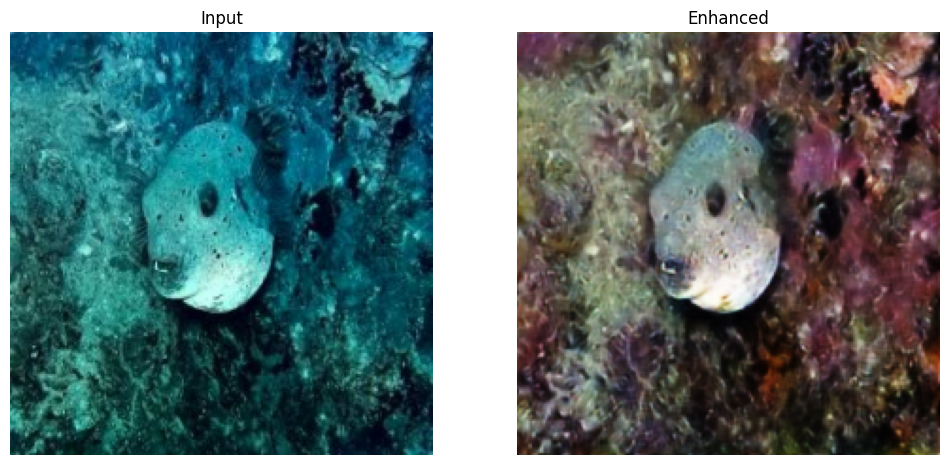

All enhanced images displayed and saved in: /content/EUVP_224/outputs


In [ ]:
# ==========================================
# Display and save all test images in full resolution
# ==========================================

import os
from PIL import Image
import matplotlib.pyplot as plt

# Create output directory if it doesn't exist
output_dir = "/content/EUVP_224/outputs"
os.makedirs(output_dir, exist_ok=True)

G.eval()  # set generator to evaluation mode
with torch.no_grad():
    for batch_idx, (low, high) in enumerate(test_loader):
        low, high = low.to(device), high.to(device)
        fake = G(low)  # generate enhanced images

        for i in range(low.size(0)):
            # Convert tensors from [-1,1] to [0,1] for visualization
            low_img  = (low[i].cpu().permute(1,2,0).numpy() * 0.5 + 0.5)
            fake_img = (fake[i].cpu().permute(1,2,0).numpy() * 0.5 + 0.5)

            # Display Input | Enhanced
            fig, axs = plt.subplots(1, 2, figsize=(12,6))
            axs[0].imshow(low_img)
            axs[0].set_title("Input")
            axs[0].axis('off')

            axs[1].imshow(fake_img)
            axs[1].set_title("Enhanced")
            axs[1].axis('off')

            plt.show()  # show image on Colab

            # Save enhanced image at full resolution
            save_path = os.path.join(output_dir, f"enhanced_batch{batch_idx+1}_img{i+1}.png")
            fake_pil = Image.fromarray((fake_img*255).astype('uint8'))
            fake_pil.save(save_path)

print(f"All enhanced images displayed and saved in: {output_dir}")


In [ ]:
# ==========================================
# Evaluation: PSNR + SSIM (full-reference) and UIQM (no-reference)
# Notes:
# - Tensors are normalized to [-1, 1] (Tanh + Normalize(0.5,0.5,0.5))
# - PSNR/SSIM should be computed in [0,1] with data_range=1.0
# - UIQM is computed per-image on [0,1] enhanced outputs (higher is usually better).
# ==========================================

!pip -q install scikit-image

import numpy as np
import torch
import math
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from skimage.filters import sobel
from skimage.color import rgb2gray

def denorm01(x: torch.Tensor) -> torch.Tensor:
    # [-1,1] -> [0,1]
    return torch.clamp((x + 1.0) / 2.0, 0.0, 1.0)

# ----------------------------
# UIQM implementation (Panetta et al.)
# ----------------------------
def eme(channel: np.ndarray, block_size: int = 8) -> float:
    h, w = channel.shape
    h_blocks = h // block_size
    w_blocks = w // block_size
    if h_blocks == 0 or w_blocks == 0:
        return 0.0
    channel = channel[:h_blocks*block_size, :w_blocks*block_size]
    em = 0.0
    eps = 1e-12
    for i in range(h_blocks):
        for j in range(w_blocks):
            block = channel[i*block_size:(i+1)*block_size, j*block_size:(j+1)*block_size]
            bmax = float(block.max())
            bmin = float(block.min())
            bmin = max(bmin, eps)
            em += math.log((bmax + eps) / (bmin + eps))
    return (2.0 / (h_blocks * w_blocks)) * em

def uicm(img01: np.ndarray) -> float:
    # colorfulness component
    R, G, B = img01[:,:,0], img01[:,:,1], img01[:,:,2]
    rg = R - G
    yb = 0.5*(R + G) - B

    rg_flat = np.sort(rg.flatten())
    yb_flat = np.sort(yb.flatten())
    alpha = 0.1  # 10% trimmed statistics
    n = rg_flat.size
    k = int(alpha * n)
    if n - 2*k > 0:
        rg_t = rg_flat[k:n-k]
        yb_t = yb_flat[k:n-k]
    else:
        rg_t = rg_flat
        yb_t = yb_flat[ ]

    mu_rg, mu_yb = float(rg_t.mean()), float(yb_t.mean())
    sig_rg, sig_yb = float(rg_t.std()), float(yb_t.std())
    return math.sqrt(mu_rg**2 + mu_yb**2) + math.sqrt(sig_rg**2 + sig_yb**2)

def uism(img01: np.ndarray, block_size: int = 8) -> float:
    # sharpness component
    R, G, B = img01[:,:,0], img01[:,:,1], img01[:,:,2]

    def sobel_mag(ch):
        return np.abs(sobel(ch))

    Rs, Gs, Bs = sobel_mag(R), sobel_mag(G), sobel_mag(B)
    R_edge = Rs * R
    G_edge = Gs * G
    B_edge = Bs * B

    r_eme = eme(R_edge, block_size)
    g_eme = eme(G_edge, block_size)
    b_eme = eme(B_edge, block_size)
    return 0.299*r_eme + 0.587*g_eme + 0.114*b_eme

def uiconm(img01: np.ndarray, block_size: int = 8) -> float:
    # contrast component (simple luminance EME approximation)
    Y = rgb2gray(img01)
    return eme(Y, block_size)

def uiqm(img01: np.ndarray) -> float:
    c1, c2, c3 = 0.0282, 0.2953, 3.5753
    return c1*uicm(img01) + c2*uism(img01) + c3*uiconm(img01)

# ----------------------------
# Loop over test set
# ----------------------------
G.eval()
psnr_scores, ssim_scores = [], []
uiqm_in_scores, uiqm_out_scores, uiqm_gt_scores = [], [], []

with torch.no_grad():
    for low, high in test_loader:
        low, high = low.to(device), high.to(device)
        fake = G(low)

        low01  = denorm01(low).cpu().numpy()
        fake01 = denorm01(fake).cpu().numpy()
        high01 = denorm01(high).cpu().numpy()

        for i in range(fake01.shape[0]):
            low_i  = low01[i].transpose(1,2,0)
            fake_i = fake01[i].transpose(1,2,0)
            high_i = high01[i].transpose(1,2,0)

            psnr_scores.append(float(psnr(high_i, fake_i, data_range=1.0)))
            ssim_scores.append(float(ssim(high_i, fake_i, data_range=1.0, channel_axis=-1)))

            # UIQM (no-reference) for input/enhanced/GT (optional but useful)
            uiqm_in_scores.append(float(uiqm(low_i)))
            uiqm_out_scores.append(float(uiqm(fake_i)))
            uiqm_gt_scores.append(float(uiqm(high_i)))

print(f"Average PSNR: {np.mean(psnr_scores):.2f} dB")
print(f"Average SSIM: {np.mean(ssim_scores):.4f}")
print(f"Average UIQM (Enhanced): {np.mean(uiqm_out_scores):.3f}")



Average PSNR: 27.09 dB
Average SSIM: 0.8757
Average UIQM (Enhanced): 9.027
